# SQUID: superconducting quantum interference device

In [ ]:
import csv
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

def load(f):
    """Read a Tektronix TDS2022C CSV export.
    Column 4 (index 3) is time, column 5 (index 4) is the scaled voltage."""
    xs, ys = [], []
    with open(f) as fh:
        r = csv.reader(fh)
        for row in r:
            if len(row) >= 5:
                try:
                    x = float(row[3])
                    y = float(row[4])
                    xs.append(x)
                    ys.append(y)
                except ValueError:
                    pass
    return np.array(xs), np.array(ys)

# ---- Load the four traces ----
# In Colab, the default root directory is '/content/'
t2, I_raw = load('/content/TEK0002.CSV')
t3, V_raw = load('/content/TEK0003.CSV')
t1, Imod_raw = load('/content/TEK0001.CSV')
t0, Vphi_raw = load('/content/TEK0000.CSV')

plt.rcParams.update({'font.size': 11, 'figure.dpi': 150})

## Figure 1: V-I characteristic, bin-averaged, with linear knee fits

V-I intercepts: I+ = 0.0690 V, I- = -2.7095 V
Branch slopes: m+ = 1.1219, m- = 1.1126


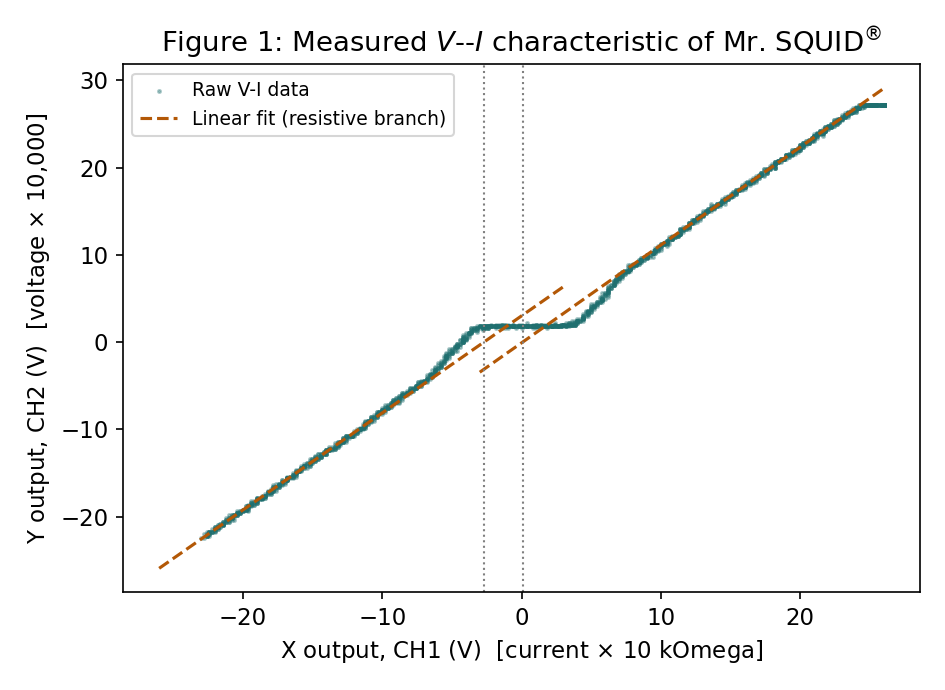

In [ ]:
# Sort by current-axis value and bin-average to collapse the rising/
# falling legs of the triangle-wave sweep onto a single curve.
order = np.argsort(I_raw)
I_s, V_s = I_raw[order], V_raw[order]

bins = np.linspace(I_s.min(), I_s.max(), 300)
bin_idx = np.digitize(I_s, bins)
V_binned = np.array([
    V_s[bin_idx == i].mean() if np.any(bin_idx == i) else np.nan
    for i in range(1, len(bins))
])
I_binned = (bins[:-1] + bins[1:]) / 2
valid = ~np.isnan(V_binned)
I_b, V_b = I_binned[valid], V_binned[valid]

# Fit the two resistive (far-from-knee) branches
mpos, bpos = np.polyfit(I_b[(I_b > 10) & (I_b < 24)],
                         V_b[(I_b > 10) & (I_b < 24)], 1)
mneg, bneg = np.polyfit(I_b[(I_b < -10) & (I_b > -24)],
                         V_b[(I_b < -10) & (I_b > -24)], 1)

Ic_pos = -bpos / mpos   # V=0 intercept, positive branch
Ic_neg = -bneg / mneg   # V=0 intercept, negative branch

fig, ax = plt.subplots(figsize=(6.3, 4.6))
ax.scatter(I_raw, V_raw, s=2, alpha=0.35, color='#1f6f6f',
           label='Raw V-I data')

xx_pos = np.linspace(-3, 26, 50)
xx_neg = np.linspace(-26, 3, 50)
ax.plot(xx_pos, mpos * xx_pos + bpos, '--', color='#b35806', lw=1.5,
        label='Linear fit (resistive branch)')
ax.plot(xx_neg, mneg * xx_neg + bneg, '--', color='#b35806', lw=1.5)

ax.axvline(Ic_pos, color='gray', ls=':', lw=1)
ax.axvline(Ic_neg, color='gray', ls=':', lw=1)

ax.set_xlabel(r'X output, CH1 (V)  [current $\times$ 10 k$\text{\Omega}$]')
ax.set_ylabel(r'Y output, CH2 (V)  [voltage $\times$ 10,000]')
ax.set_title(r'Figure 1: Measured $V$--$I$ characteristic of Mr. SQUID$^{\circledR}$')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.savefig('fig1_VI.png')
plt.close()

print(f"V-I intercepts: I+ = {Ic_pos:.4f} V, I- = {Ic_neg:.4f} V")
print(f"Branch slopes: m+ = {mpos:.4f}, m- = {mneg:.4f}")

# Display the figure inline in Google Colab
from IPython.display import Image, display
display(Image('fig1_VI.png'))

## Figure 2: V-Phi characteristic, one clean monotonic sweep leg

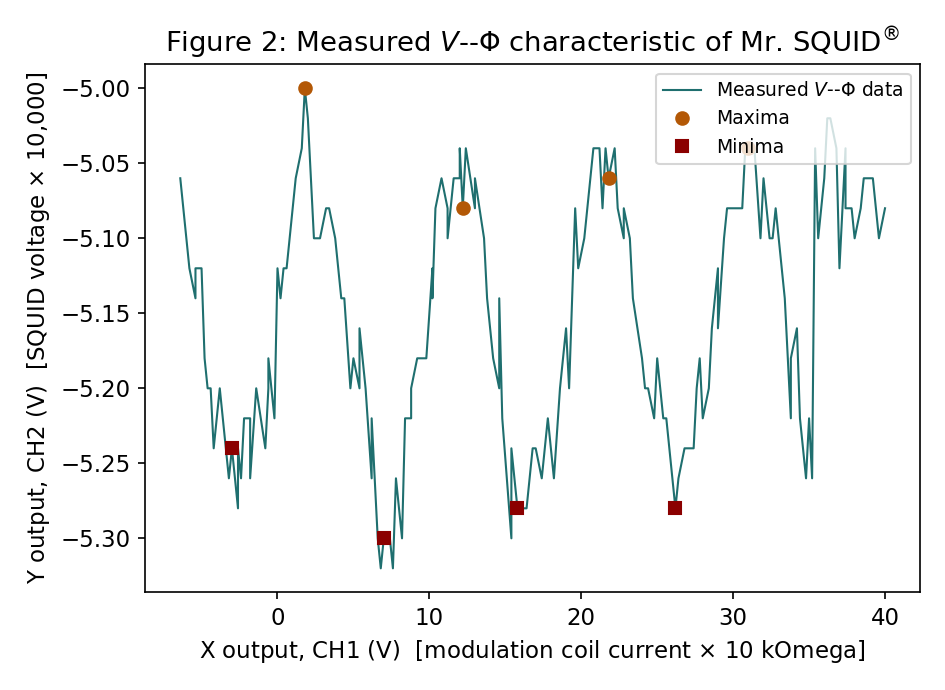

In [ ]:
# Isolate a single falling leg of the modulation-coil triangle wave
# (identified by inspecting the CH1-vs-time trace).
mask = (t1 >= -0.0277) & (t1 <= -0.0206)
II = Imod_raw[mask]
VV = Vphi_raw[mask]

order2 = np.argsort(II)
I_s2, V_s2 = II[order2], VV[order2]

# Peak/trough X-positions and Y-values, read off the curve
# (see report Section 5.3 for how these were located).
peak_I = np.array([1.8, 12.2, 21.8, 31.0])
peak_V = np.array([-5.00, -5.08, -5.06, -5.04])
trough_I = np.array([-3.0, 7.0, 15.8, 26.2])
trough_V = np.array([-5.24, -5.30, -5.28, -5.28])

fig2, ax2 = plt.subplots(figsize=(6.3, 4.6))
ax2.plot(I_s2, V_s2, '-', lw=1, color='#1f6f6f',
         label=r'Measured $V$--$\Phi$ data')
ax2.plot(peak_I, peak_V, 'o', color='#b35806', ms=6, label='Maxima')
ax2.plot(trough_I, trough_V, 's', color='#8b0000', ms=6, label='Minima')

for i in range(len(peak_I) - 1):
    ax2.annotate('', xy=(peak_I[i + 1], -4.95), xytext=(peak_I[i], -4.95),
                 arrowprops=dict(arrowstyle='<->', color='gray'))

ax2.set_xlabel(r'X output, CH1 (V)  [modulation coil current $\times$ 10 k$\text{\Omega}$]')
ax2.set_ylabel(r'Y output, CH2 (V)  [SQUID voltage $\times$ 10,000]')
ax2.set_title(r'Figure 2: Measured $V$--$\Phi$ characteristic of Mr. SQUID$^{\circledR}$')
ax2.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig('fig2_Vphi.png')
plt.close()

# Display the figure inline in Google Colab
from IPython.display import Image, display
display(Image('fig2_Vphi.png'))

In [ ]:
period_mean = np.mean(np.concatenate([np.diff(peak_I), np.diff(trough_I)]))
period_std = np.std(np.concatenate([np.diff(peak_I), np.diff(trough_I)]), ddof=1)
print(f"V-Phi period: {period_mean:.3f} +/- {period_std:.3f} V (raw CH1)")
print("Figures saved: fig1_VI.png, fig2_Vphi.png")

V-Phi period: 9.733 +/- 0.653 V (raw CH1)
Figures saved: fig1_VI.png, fig2_Vphi.png
